# Data checks

Each section checks facts the design notes rely on, straight from the raw files in `data/raw/` (run `python download_data.py` first). Section 7 also asks Environment Canada's public station list, because the rain stations were chosen from it.

Read-only: nothing here changes a file. Run top to bottom.

In [1]:
import math
import json
import urllib.request
import pandas as pd
from pipeline import config

RAW = config.RAW
YEARS = config.YEARS
TARGETS = {"E316370": "Clark Drive", "E283549": "Tsawwassen"}
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)


def hours_in_year(year):
    return 8784 if year % 4 == 0 else 8760


def haversine_km(lat1, lon1, lat2, lon2):
    """Distance along the Earth's surface, in km."""
    r = math.radians
    a = math.sin(r(lat2 - lat1) / 2) ** 2 + math.cos(r(lat1)) * math.cos(r(lat2)) * math.sin(r(lon2 - lon1) / 2) ** 2
    return 6371 * 2 * math.asin(math.sqrt(a))


def read_yearly(folder, cols):
    """All yearly files of one source, with the file's year in a column."""
    parts = [pd.read_csv(RAW / folder / f"{y}.csv", usecols=cols, encoding="utf-8", low_memory=False).assign(year=y) for y in YEARS]
    return pd.concat(parts, ignore_index=True)


def get_json(url):
    with urllib.request.urlopen(url, timeout=60) as response:
        return json.load(response)

## 1. NO2 raw files

Facts checked: rows and stations per year; one unit; 2024 has 28 stations × 8,784 hours; negative values (notes: 116); no duplicate (station, hour) pairs.

In [2]:
no2 = read_yearly("no2", ["DATE_PST", "EMS_ID", "STATION_NAME", "RAW_VALUE", "UNIT", "INSTRUMENT"])
print("rows:", len(no2), "| readings with a value:", no2.RAW_VALUE.notna().sum())
print("units:", no2.UNIT.dropna().unique())
print(no2.groupby("year").agg(rows=("EMS_ID", "size"), stations=("EMS_ID", "nunique")))

rows: 2443479 | readings with a value: 2365512
units: <ArrowStringArray>
['ppb']
Length: 1, dtype: str
        rows  stations
year                  
2015  244897        29
2016  245952        28
2017  245280        28
2018  245281        29
2019  243443        28
2020  236861        27
2021  245253        28
2022  245280        28
2023  245280        28
2024  245952        28


In [3]:
y24 = no2[no2.year == 2024]
print("2024:", y24.EMS_ID.nunique(), "stations x", hours_in_year(2024), "hours =", y24.EMS_ID.nunique() * hours_in_year(2024), "| rows:", len(y24))

neg = no2[no2.RAW_VALUE < 0]
print("negative values:", len(neg), "| lowest:", neg.RAW_VALUE.min())
print(neg.groupby("year").size().rename("negatives"))

print("duplicate (station, hour) pairs:", no2.duplicated(["EMS_ID", "DATE_PST"]).sum())

2024: 28 stations x 8784 hours = 245952 | rows: 245952
negative values: 116 | lowest: -0.04946202
year
2015     1
2016    16
2017    56
2018     9
2019    19
2020     2
2021    13
Name: negatives, dtype: int64
duplicate (station, hour) pairs: 0


## 2. Station list

Facts checked: 599 rows but 410 stations; the repeats are "Met" and "_OLD" entries or suffixed entries at the same site; after the cleaning rule (drop "Met" and "_OLD", then one row per station) every NO2 station has coordinates; the IDs of the two targets.

In [4]:
st = pd.read_csv(RAW / "stations" / "bc_air_monitoring_stations.csv", encoding="utf-8")
print("rows:", len(st), "| distinct EMS_ID:", st.EMS_ID.nunique())

no2_ids = set(no2.EMS_ID)
repeats = st[st.EMS_ID.isin(no2_ids) & st.EMS_ID.duplicated(keep=False)].sort_values("EMS_ID")
print("\nNO2 stations with more than one row in the list:")
print(repeats[["EMS_ID", "STATION_NAME_FULL", "LAT", "LONG", "STATUS"]].to_string(index=False))

rows: 599 | distinct EMS_ID: 410

NO2 stations with more than one row in the list:
 EMS_ID                   STATION_NAME_FULL       LAT        LONG STATUS
0220204       Powell River Cranberry Lake_1 49.866905 -124.521819    OFF
0220204      Powell River Cranberry Lake_60 49.866905 -124.521819    OFF
0220205             Powell River Wildwood_1 49.886894 -124.558104    OFF
0220205            Powell River Wildwood_60 49.886894 -124.558104    OFF
0310162         Port Moody Rocky Point Park 49.280900 -122.849300     ON
0310162     Port Moody Rocky Point Park Met 49.280800 -122.849200     ON
E220891                  Chilliwack Airport 49.155800 -121.940300     ON
E220891              Chilliwack Airport_OLD 49.156100 -121.940600    OFF
E232244     Pitt Meadows Meadowlands School 49.245200 -122.708900     ON
E232244 Pitt Meadows Meadowlands School_OLD 49.245300 -122.708900    OFF
E289309        Abbotsford A Columbia Street 49.021500 -122.326500     ON
E289309    Abbotsford A Columbia Street M

In [5]:
name = st.STATION_NAME_FULL
stations = st[~name.str.endswith(" Met") & ~name.str.endswith("_OLD")].drop_duplicates("EMS_ID") # the cleaning rule
stations = stations[stations.EMS_ID.isin(no2_ids)].set_index("EMS_ID")
print("NO2 stations:", len(no2_ids), "| with one row after the rule:", len(stations), "| missing coordinates:", stations[["LAT", "LONG"]].isna().any(axis=1).sum())
print(stations.loc[list(TARGETS), ["STATION_NAME_FULL", "LAT", "LONG"]])

NO2 stations: 32 | with one row after the rule: 32 | missing coordinates: 0
             STATION_NAME_FULL      LAT      LONG
EMS_ID                                           
E316370  Vancouver Clark Drive  49.2603 -123.0778
E283549             Tsawwassen  49.0099 -123.0820


## 3. Highest NO2 values

Facts checked: the highest hour is 138 ppb (North Vancouver Second Narrows, Jul 7 2023); 3 hours above 100 ppb; 23 above 80; Clark Drive's highest is about 85.

In [6]:
print(no2.nlargest(5, "RAW_VALUE")[["DATE_PST", "STATION_NAME", "RAW_VALUE"]].to_string(index=False))
print("\nhours above 100 ppb:", (no2.RAW_VALUE > 100).sum(), "| above 80 ppb:", (no2.RAW_VALUE > 80).sum())
print("highest at Clark Drive:", no2.loc[no2.EMS_ID == "E316370", "RAW_VALUE"].max())

        DATE_PST                   STATION_NAME  RAW_VALUE
2023-07-07 15:00 North Vancouver Second Narrows  138.06320
2019-07-29 13:00 North Vancouver Second Narrows  105.35410
2019-05-29 15:00 North Vancouver Second Narrows  100.29140
2019-06-26 11:00 North Vancouver Second Narrows   98.92755
2023-06-07 20:00 North Vancouver Second Narrows   93.34052

hours above 100 ppb: 3 | above 80 ppb: 23
highest at Clark Drive: 84.91236


## 4. Instrument labels at the targets

Facts checked: how many stations have more than one `INSTRUMENT` label; at the two targets, which label each year has. If the label switches back and forth by year, it is a labelling change in the files, not a replaced analyser.

In [7]:
labels = no2.groupby("EMS_ID").INSTRUMENT.nunique()
print("stations with more than one INSTRUMENT label:", (labels > 1).sum(), "of", len(labels))

stations with more than one INSTRUMENT label: 22 of 32


In [8]:
for ems, label in TARGETS.items():
    print(f"\n{label} ({ems}): readings per INSTRUMENT label and year")
    print(pd.crosstab(no2.loc[no2.EMS_ID == ems, "year"], no2.loc[no2.EMS_ID == ems, "INSTRUMENT"]))


Clark Drive (E316370): readings per INSTRUMENT label and year
INSTRUMENT  NOX_TEI42i  UNSPECIFIED
year                               
2015                 0         8760
2016                 0         8784
2017                 0         8760
2018                 0         8760
2019                 0         8760
2020                 0         8784
2021              8760            0
2022              8760            0
2023                 0         8760
2024              8784            0

Tsawwassen (E283549): readings per INSTRUMENT label and year
INSTRUMENT  NOX_API200E  UNSPECIFIED
year                                
2015                  0         8760
2016                  0         8784
2017                  0         8760
2018                  0         8760
2019                  0         8760
2020                  0         8784
2021               8760            0
2022               8760            0
2023                  0         8760
2024               8784            0

## 5. O3

Facts checked: one unit (ppb); % of hours with a value at each target, per year.

In [9]:
o3 = read_yearly("o3", ["DATE_PST", "EMS_ID", "RAW_VALUE", "UNIT"])
print("units:", o3.UNIT.dropna().unique())
print("duplicate (station, hour) pairs at the targets:", o3[o3.EMS_ID.isin(TARGETS)].duplicated(["EMS_ID", "DATE_PST"]).sum())
filled = o3[o3.EMS_ID.isin(TARGETS) & o3.RAW_VALUE.notna()].groupby(["year", "EMS_ID"]).size().unstack()
coverage = filled.div([hours_in_year(y) for y in filled.index], axis=0).mul(100).round(1).rename(columns=TARGETS)
print("\n% of hours with an O3 value:")
print(coverage)

units: <ArrowStringArray>
['ppb']
Length: 1, dtype: str
duplicate (station, hour) pairs at the targets: 0

% of hours with an O3 value:
EMS_ID  Tsawwassen  Clark Drive
year                           
2015          97.8         61.1
2016          96.7         95.7
2017          97.2         93.8
2018          98.8         96.0
2019          98.8         98.2
2020          99.4         99.1
2021          99.3         98.2
2022          98.4         96.9
2023          99.7         98.0
2024          98.4         99.8


## 6. YVR weather

Facts checked: rain (`PRECIP_AMOUNT`) is empty in every year; missing hours per year; wind direction 0 goes with wind speed 0 (so 0 means calm, not north); wind direction is in tens of degrees (max 36).

In [10]:
wx = read_yearly("weather_yvr", ["UTC_DATE", "PRECIP_AMOUNT", "WIND_DIRECTION", "WIND_SPEED"])
per_year = wx.groupby("year").agg(rows=("UTC_DATE", "size"), rain_values=("PRECIP_AMOUNT", "count"))
per_year["missing_hours"] = [hours_in_year(y) for y in per_year.index] - per_year.rows
print(per_year)
print("total missing hours:", per_year.missing_hours.sum())

dir0 = wx.WIND_DIRECTION == 0
speed0 = wx.WIND_SPEED == 0
print("\nrows with direction 0:", dir0.sum(), "| speed 0:", speed0.sum(), "| same rows:", (dir0 == speed0).all())
print("largest wind direction value:", wx.WIND_DIRECTION.max())

      rows  rain_values  missing_hours
year                                  
2015  8748            0             12
2016  8781            0              3
2017  8758            0              2
2018  8756            0              4
2019  8760            0              0
2020  8783            0              1
2021  8757            0              3
2022  8747            0             13
2023  8752            0              8
2024  8766            0             18
total missing hours: 64

rows with direction 0: 2947 | speed 0: 2935 | same rows: False
largest wind direction value: 36


In [11]:
odd = wx[dir0 != speed0] # hours where only one of the two is 0
print("hours where only one of direction and speed is 0:", len(odd))
print(odd[["UTC_DATE", "WIND_DIRECTION", "WIND_SPEED"]].to_string(index=False))

hours where only one of direction and speed is 0: 12
           UTC_DATE  WIND_DIRECTION  WIND_SPEED
2018-08-10T09:00:00               0         1.0
2018-09-05T10:00:00               0         1.0
2018-09-18T13:00:00               0         1.0
2018-09-27T10:00:00               0         1.0
2018-10-12T04:00:00               0         1.0
2018-10-15T05:00:00               0         1.0
2018-11-08T03:00:00               0         1.0
2018-11-20T08:00:00               0         1.0
2020-03-29T23:00:00               0         NaN
2020-04-06T01:00:00               0         NaN
2021-09-03T23:00:00               0         NaN
2023-03-24T18:00:00               0         NaN


## 7. Rain stations: how they were chosen

Neither target measures rain, and YVR's rain is empty (section 6). This section repeats the search behind the choice:
1. Ask ECCC's station list for every station in a box around Metro Vancouver.
2. Keep stations with hourly data covering 2015–2024.
3. Measure each one's distance to both targets, from coordinates.
4. Ask for January 2024 at each one and count the hours with a rain value.

Needs internet.

In [12]:
box = "-123.35,48.95,-122.75,49.40" # lon min, lat min, lon max, lat max
found = get_json(f"https://api.weather.gc.ca/collections/climate-stations/items?bbox={box}&limit=500&f=json")["features"]
rows = []
for f in found:
    p = f["properties"]
    if p.get("HAS_HOURLY_DATA") != "Y" or not p.get("HLY_FIRST_DATE") or not p.get("HLY_LAST_DATE"):
        continue
    if p["HLY_FIRST_DATE"][:4] > "2015" or p["HLY_LAST_DATE"][:4] < "2024": # must cover 2015-2024
        continue
    lon, lat = f["geometry"]["coordinates"]
    row = {"station": p["STATION_NAME"], "climate_id": p["CLIMATE_IDENTIFIER"], "hourly_from": p["HLY_FIRST_DATE"][:10], "hourly_to": p["HLY_LAST_DATE"][:10]}
    for ems, label in TARGETS.items():
        row[f"km_to_{label}"] = round(haversine_km(lat, lon, stations.loc[ems, "LAT"], stations.loc[ems, "LONG"]), 1)
    rows.append(row)
candidates = pd.DataFrame(rows)
print("stations in the box:", len(found), "| hourly, covering 2015-2024:", len(candidates))

stations in the box: 186 | hourly, covering 2015-2024: 6


In [13]:
def rain_hours_jan_2024(climate_id):
    url = f"https://api.weather.gc.ca/collections/climate-hourly/items?CLIMATE_IDENTIFIER={climate_id}&LOCAL_YEAR=2024&LOCAL_MONTH=1&limit=1000&f=json"
    props = [f["properties"] for f in get_json(url)["features"]]
    return len(props), sum(p.get("PRECIP_AMOUNT") is not None for p in props)


counts = [rain_hours_jan_2024(c) for c in candidates.climate_id]
candidates["hours_jan_2024"] = [c[0] for c in counts]
candidates["hours_with_rain_value"] = [c[1] for c in counts]
print(candidates.sort_values("km_to_Clark Drive").to_string(index=False))

                       station climate_id hourly_from  hourly_to  km_to_Clark Drive  km_to_Tsawwassen  hours_jan_2024  hours_with_rain_value
          VANCOUVER HARBOUR CS    1108446  1976-01-20 2026-11-24                5.0              31.9             738                    738
              VANCOUVER INTL A    1108395  2013-06-11 2026-11-24               10.6              21.8             742                      0
      VANCOUVER SEA ISLAND CCG    1108380  2013-03-20 2026-11-24               11.7              20.7             740                    740
            WEST VANCOUVER AUT    1108824  1994-02-01 2026-11-24               12.8              38.4             744                    744
               DELTA BURNS BOG    1102415  2010-11-19 2026-11-24               15.9              14.1             744                    744
WHITE ROCK CAMPBELL SCIENTIFIC    1108910  1994-02-01 2026-11-24               34.4              21.8             744                    581


In [14]:
has_rain = candidates[candidates.hours_with_rain_value > 0]
for label in TARGETS.values():
    nearest = has_rain.nsmallest(2, f"km_to_{label}")
    print(f"{label}: nearest with rain = {nearest.iloc[0].station} ({nearest.iloc[0][f'km_to_{label}']} km), next = {nearest.iloc[1].station} ({nearest.iloc[1][f'km_to_{label}']} km)")

Clark Drive: nearest with rain = VANCOUVER HARBOUR CS (5.0 km), next = VANCOUVER SEA ISLAND CCG (11.7 km)
Tsawwassen: nearest with rain = DELTA BURNS BOG (14.1 km), next = VANCOUVER SEA ISLAND CCG (20.7 km)


## 8. Downloaded rain files

Facts checked: each file has the station's coordinates; % of hours with a rain value per year; the monthly gaps (Harbour Feb–Apr 2020, Sea Island Nov 2019 – Jan 2020). A station that isn't downloaded yet is skipped.

Last cell: the rain plan (each target's nearest station, gaps filled from the next one). Counts the hours where no station in the plan has a value, by month.

In [15]:
rain_folders = {"rain_harbour": "Harbour", "rain_burns_bog": "Burns Bog", "rain_sea_island": "Sea Island"}
rain = {}
for folder, label in rain_folders.items():
    if not (RAW / folder).exists():
        print(f"{label}: not downloaded yet ({folder}/)")
        continue
    rain[label] = read_yearly(folder, ["UTC_DATE", "LOCAL_MONTH", "PRECIP_AMOUNT", "LATITUDE_DECIMAL_DEGREES", "LONGITUDE_DECIMAL_DEGREES"])
    coords = rain[label][["LATITUDE_DECIMAL_DEGREES", "LONGITUDE_DECIMAL_DEGREES"]].drop_duplicates()
    print(f"{label}: coordinates in the file = {coords.values.tolist()}")

yearly = pd.DataFrame({label: df.groupby("year").PRECIP_AMOUNT.count() for label, df in rain.items()})
yearly = yearly.div([hours_in_year(y) for y in yearly.index], axis=0).mul(100).round(1)
print("\n% of hours with a rain value:")
print(yearly)

Harbour: coordinates in the file = [[49.29535277777778, -123.12186944444444]]
Burns Bog: coordinates in the file = [[49.12584805555556, -123.00224583333333]]
Sea Island: coordinates in the file = [[49.1825, -123.1872361111111]]

% of hours with a rain value:
      Harbour  Burns Bog  Sea Island
year                                
2015     99.6       99.4        99.7
2016     99.8       93.8        99.9
2017     99.9       99.6        99.6
2018     99.8       99.9        98.9
2019     99.6       40.7        84.2
2020     68.8       67.0        90.1
2021     95.8       99.8        94.2
2022     99.8       99.8        99.7
2023    100.0       99.9        99.9
2024     99.8       99.9        99.5


In [16]:
for label, df in rain.items():
    part = df[df.year.isin([2019, 2020])]
    monthly = part.groupby(["year", "LOCAL_MONTH"]).PRECIP_AMOUNT.count().unstack()
    days = pd.DataFrame({y: pd.Series(pd.date_range(f"{y}-01-01", f"{y}-12-31", freq="D").month).value_counts().sort_index() * 24 for y in [2019, 2020]}).T
    print(f"\n{label}: % of hours with a rain value, by month")
    print(monthly.div(days).mul(100).round(0))


Harbour: % of hours with a rain value, by month
LOCAL_MONTH     1      2      3      4      5      6      7      8      9      10     11     12
year                                                                                           
2019         100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0   96.0
2020          17.0    0.0    0.0    4.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0  100.0

Burns Bog: % of hours with a rain value, by month
LOCAL_MONTH     1     2      3      4      5     6      7      8      9      10     11     12
year                                                                                         
2019         100.0  99.0  100.0  100.0   92.0   0.0    0.0    0.0    0.0    0.0    0.0    0.0
2020           0.0   0.0    0.0    1.0  100.0  99.0  100.0  100.0  100.0  100.0  100.0  100.0

Sea Island: % of hours with a rain value, by month
LOCAL_MONTH    1      2      3      4      5      6      7      8      9      10     11 

In [17]:
def hourly_rain(label):
    df = rain[label]
    s = df.assign(t=pd.to_datetime(df.UTC_DATE)).set_index("t").PRECIP_AMOUNT
    return s[~s.index.duplicated()]


hours = pd.date_range("2015-01-01 08:00", "2025-01-01 07:00", freq="h") # every hour of 2015-2024 local (UTC-8), in UTC
series = {label: hourly_rain(label).reindex(hours) for label in rain}
plans = {
    "Clark Drive": ["Harbour", "Sea Island"],
    "Tsawwassen": ["Burns Bog", "Sea Island"],
    "Tsawwassen, Harbour as a third backup": ["Burns Bog", "Sea Island", "Harbour"],
}
for name, order in plans.items():
    filled = series[order[0]]
    for backup in order[1:]:
        filled = filled.fillna(series[backup])
    gap = filled.isna()
    by_month = gap.groupby(gap.index.to_period("M")).mean().mul(100).round(0)
    print(f"\n{name}: {' -> '.join(order)} | hours with no rain value: {gap.sum()} of {len(hours)}")
    print("months with 10% or more of hours missing:")
    print(by_month[by_month >= 10].to_string() if (by_month >= 10).any() else "none")


Clark Drive: Harbour -> Sea Island | hours with no rain value: 858 of 87672
months with 10% or more of hours missing:
2020-01    83.0
2020-02    17.0
2021-01    11.0
Freq: M

Tsawwassen: Burns Bog -> Sea Island | hours with no rain value: 2251 of 87672
months with 10% or more of hours missing:
2019-11     87.0
2019-12    100.0
2020-01    100.0
2020-02     17.0
Freq: M

Tsawwassen, Harbour as a third backup: Burns Bog -> Sea Island -> Harbour | hours with no rain value: 773 of 87672
months with 10% or more of hours missing:
2020-01    83.0
2020-02    17.0
Freq: M


## 9. Agassiz and Clark Drive's neighbours

Facts checked:
- the two Agassiz sites are 0.90 km apart
- the old site (Municipal Hall) has data up to 2023 and none in 2024; the new site (Centennial Park) has data only from 2024. That is why they are merged into one station (D4)
- how far Agassiz is from the two targets
- the station nearest Clark Drive is Robson Square (4.03 km)

In [18]:
agassiz = stations[stations.STATION_NAME_FULL.str.contains("Agassiz")]
print(agassiz[["STATION_NAME_FULL", "LAT", "LONG"]])
a, b = agassiz.index[:2]
print("distance between them:", round(haversine_km(agassiz.loc[a, "LAT"], agassiz.loc[a, "LONG"], agassiz.loc[b, "LAT"], agassiz.loc[b, "LONG"]), 2), "km")

clark = stations.loc["E316370"]
dist = stations.apply(lambda s: haversine_km(clark.LAT, clark.LONG, s.LAT, s.LONG), axis=1).drop("E316370")
print("\nnearest stations to Clark Drive (km):")
print(pd.concat([stations.STATION_NAME_FULL, dist.round(2).rename("km")], axis=1).loc[dist.nsmallest(5).index])

               STATION_NAME_FULL        LAT        LONG
EMS_ID                                                 
598      Agassiz Centennial Park  49.238360 -121.774780
E293810   Agassiz Municipal Hall  49.238032 -121.762334
distance between them: 0.9 km

nearest stations to Clark Drive (km):
                      STATION_NAME_FULL    km
EMS_ID                                       
0310174         Vancouver Robson Square  4.03
0310179  North Vancouver Second Narrows  6.19
E209177      North Vancouver Mahon Park  7.10
0310177         Burnaby Kensington Park  8.05
E207418                   Burnaby South  8.36


In [19]:
old_site, new_site = "E293810", "598" # Municipal Hall, Centennial Park
has_value = no2[no2.EMS_ID.isin([old_site, new_site]) & no2.RAW_VALUE.notna()]
per_year = has_value.groupby(["year", "EMS_ID"]).size().unstack(fill_value=0).reindex(YEARS, fill_value=0)
print("Agassiz: readings with a value, per year")
print(per_year.rename(columns=stations.STATION_NAME_FULL))

for ems, label in TARGETS.items():
    km = haversine_km(stations.loc[ems, "LAT"], stations.loc[ems, "LONG"], stations.loc[old_site, "LAT"], stations.loc[old_site, "LONG"])
    print(f"Agassiz to {label}: {km:.1f} km")

Agassiz: readings with a value, per year
EMS_ID  Agassiz Centennial Park  Agassiz Municipal Hall
year                                                   
2015                          0                    8578
2016                          0                    8626
2017                          0                    8599
2018                          0                    8678
2019                          0                    8694
2020                          0                    8663
2021                          0                    8729
2022                          0                    8658
2023                          0                    8734
2024                       8714                       0
Agassiz to Clark Drive: 95.5 km
Agassiz to Tsawwassen: 99.3 km


## 10. Cleaned grid: hours with no weather and no rain

Reads `data/clean/clean_grid.parquet` (run `python clean_data.py` first). Lists every hour where all YVR weather and all three rain columns are blank, in local standard time (UTC−8).

In [20]:
grid = pd.read_parquet(config.CLEAN / "clean_grid.parquet")
weather_cols = [c for c in grid.columns if c.startswith(("yvr_", "rain_"))]
all_blank = grid[weather_cols].isna().all(axis=1)
print("hours with every weather and rain column blank:", int(all_blank.sum()))
print(grid.index[all_blank].tz_convert("Etc/GMT+8").strftime("%Y-%m-%d %H:%M").to_series(index=None).to_string(index=False))

hours with every weather and rain column blank: 7
start_utc
2022-04-22 10:00
2022-04-22 11:00
2022-04-22 12:00
2022-04-22 13:00
2022-04-22 14:00
2022-04-22 15:00
2024-12-31 23:00


## 11. Inspecting Cleaned Grid

How full each group of columns is, and the typical values at the two targets and in the weather.

In [21]:
groups = {"NO2": "no2_", "O3": "o3_", "YVR weather": "yvr_", "rain": "rain_"}
for label, prefix in groups.items():
    cols = [c for c in grid.columns if c.startswith(prefix)]
    filled = grid[cols].notna().mean().mul(100)
    print(f"{label}: {len(cols)} columns | % of hours with a value: lowest {filled.min():.1f}, median {filled.median():.1f}, highest {filled.max():.1f}")
print()
print(grid[["no2_E316370", "no2_E283549", "yvr_temp_c", "yvr_wind_speed_ms", "rain_harbour_mm", "rain_burns_bog_mm"]].describe().round(2))

NO2: 31 columns | % of hours with a value: lowest 9.4, median 98.0, highest 98.9
O3: 27 columns | % of hours with a value: lowest 9.5, median 97.9, highest 98.8
YVR weather: 5 columns | % of hours with a value: lowest 96.6, median 99.9, highest 99.9
rain: 3 columns | % of hours with a value: lowest 90.0, median 96.3, highest 96.6

       no2_E316370  no2_E283549  yvr_temp_c  yvr_wind_speed_ms  rain_harbour_mm  rain_burns_bog_mm
count     82099.00     86573.00    87606.00           87603.00         84413.00           78875.00
mean         17.75         6.08       10.78               3.76             0.17               0.13
std           9.58         5.59        6.27               2.16             0.63               0.53
min           0.14         0.01      -14.50               0.00             0.00               0.00
25%          10.36         2.13        6.30               2.22             0.00               0.00
50%          16.74         4.09       10.40               3.61           

## 12. Flags: how many, where, and at what time of day

A flag is a question, not a verdict. Cleaning flagged hours three ways and changed nothing:
- **spike:** one hour far above the hours around it
- **too_high:** above 100 ppb
- **off_neighbours:** far from the average of the station's 2 nearest stations for 6 hours or more in a row

Spikes per 1,000 hours puts stations with more or fewer readings on the same scale.

In [22]:
import matplotlib.pyplot as plt

flags = pd.read_parquet(config.CLEAN / "flags.parquet")
station_table = pd.read_parquet(config.CLEAN / "stations.parquet")
names = station_table.set_index("station_id")["name"]

print(flags.groupby("check").size().rename("flagged hours").to_string())

hours_with_reading = grid.filter(like="no2_").notna().sum().rename(lambda c: c.split("_", 1)[1])
per_station = flags.pivot_table(index="station_id", columns="check", values="start_utc", aggfunc="count", fill_value=0)
per_station["spikes_per_1000_h"] = (per_station["spike"] / hours_with_reading.reindex(per_station.index) * 1000).round(1)
per_station.index = [f"{names[i]} ({i})" for i in per_station.index]
print()
print(per_station.sort_values("spikes_per_1000_h", ascending=False).to_string())

check
off_neighbours     452
spike             3413
too_high             3

check                                                       off_neighbours  spike  too_high  spikes_per_1000_h
Langdale Elementary (E222778)                                            0    564         0                6.9
Pitt Meadows Meadowlands School (E232244)                               12    321         0                3.8
Powell River Wildwood (0220205)                                          0     45         0                3.2
Mission School Works Yard (E302130)                                     25    215         0                2.5
Tsawwassen (E283549)                                                    26    220         0                2.5
Powell River Cranberry Lake (0220204)                                    0     48         0                2.1
Agassiz Municipal Hall / Agassiz Centennial Park (E293810)              38    161         0                1.9
Abbotsford A Columbia Street (E28930

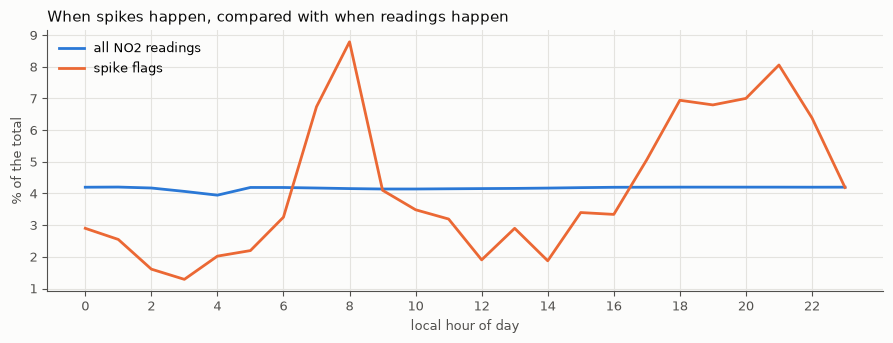

In [23]:
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"] # categorical slots 1-3
INK, INK_2, GRID_LINE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID_LINE, "grid.linewidth": 0.8,
    "axes.titlesize": 11, "axes.titlecolor": INK, "font.size": 9,
})

local_hour = grid.index.tz_convert(config.LOCAL_TZ).hour
readings_by_hour = grid.filter(like="no2_").notna().sum(axis=1).groupby(local_hour).sum()
share_all = readings_by_hour / readings_by_hour.sum() * 100
spike_hours = flags.loc[flags.check == "spike", "start_utc"].dt.tz_convert(config.LOCAL_TZ).dt.hour
share_spikes = spike_hours.value_counts(normalize=True).reindex(range(24), fill_value=0) * 100

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(share_all.index, share_all.values, color=SERIES[0], lw=2, label="all NO2 readings")
ax.plot(share_spikes.index, share_spikes.values, color=SERIES[1], lw=2, label="spike flags")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("local hour of day")
ax.set_ylabel("% of the total")
ax.set_title("When spikes happen, compared with when readings happen", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

## 13. A chart for looking at one flagged hour

`show_episode(station, time)` draws three panels around a flagged hour (local time):
1. **NO2** at the flagged station and its 2 nearest stations. Circles mark this station's flagged hours.
2. **O3** at the flagged station, if it measures ozone.
3. **Wind speed** at YVR.

**Clues that a reading is real pollution:**
- The neighbours rise at the same time (a regional episode).
- O3 dips as NO2 jumps. Fresh exhaust contains NO, which uses up ozone, so a real burst of traffic or ship exhaust lowers O3 at the same station.
- The wind is calm. Still air traps pollution near the ground.
- It happens at rush hour at a road station.

**Clues that it may be a fault:**
- The station moves alone, at an odd time, with its neighbours flat.
- A flat line, or a step up or down that never comes back.
- O3 doesn't react at all to a big NO2 jump.

None of these is proof on its own. Look at several together.

In [24]:
distances = pd.read_parquet(config.CLEAN / "station_distances.parquet")


def to_local(times):
    return times.tz_convert(config.LOCAL_TZ).tz_localize(None)


def show_episode(station_id, when_utc, before=12, after=12):
    when = pd.Timestamp(when_utc)
    when = when.tz_localize("UTC") if when.tzinfo is None else when
    part = grid[(grid.index >= when - pd.Timedelta(hours=before)) & (grid.index <= when + pd.Timedelta(hours=after))]
    t = to_local(part.index)
    nearest = distances.loc[station_id].drop(station_id).nsmallest(2)

    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.4, 1.4]})
    ax = axes[0]
    ax.plot(t, part[f"no2_{station_id}"], color=SERIES[0], lw=2, label=f"{names[station_id]} (flagged station)")
    for color, (other, km) in zip(SERIES[1:], nearest.items()):
        ax.plot(t, part[f"no2_{other}"], color=color, lw=1.5, label=f"{names[other]}, {km:.1f} km away")
    here = flags[(flags.station_id == station_id) & flags.start_utc.isin(part.index)]
    ax.scatter(to_local(pd.DatetimeIndex(here.start_utc)), here.no2_ppb, s=70, facecolor="none", edgecolor=INK, lw=1.5, zorder=3, label="flagged hour")
    ax.set_ylabel("NO2 (ppb)")
    ax.legend(frameon=False, loc="upper left", fontsize=8)
    ax.set_title(f"{names[station_id]}: {when.tz_convert(config.LOCAL_TZ):%Y-%m-%d %H:%M} local", loc="left")

    o3_column = f"o3_{station_id}"
    if o3_column in grid.columns:
        axes[1].plot(t, part[o3_column], color=SERIES[0], lw=1.5)
    else:
        axes[1].text(0.01, 0.5, "no O3 at this station", transform=axes[1].transAxes, color=INK_2)
    axes[1].set_ylabel("O3 (ppb)")
    axes[2].plot(t, part["yvr_wind_speed_ms"], color=INK_2, lw=1.5)
    axes[2].set_ylabel("YVR wind (m/s)")
    axes[2].set_xlabel("local time")
    fig.tight_layout()
    plt.show()

## 14. Too high: the 3 hours above 100 ppb

Check: **too_high**, a reading above 100 ppb. Only one station has any: North Vancouver Second Narrows, next to the bridge and the port (its row in the section 12 table, `too_high` = 3). ±24 hours around each.

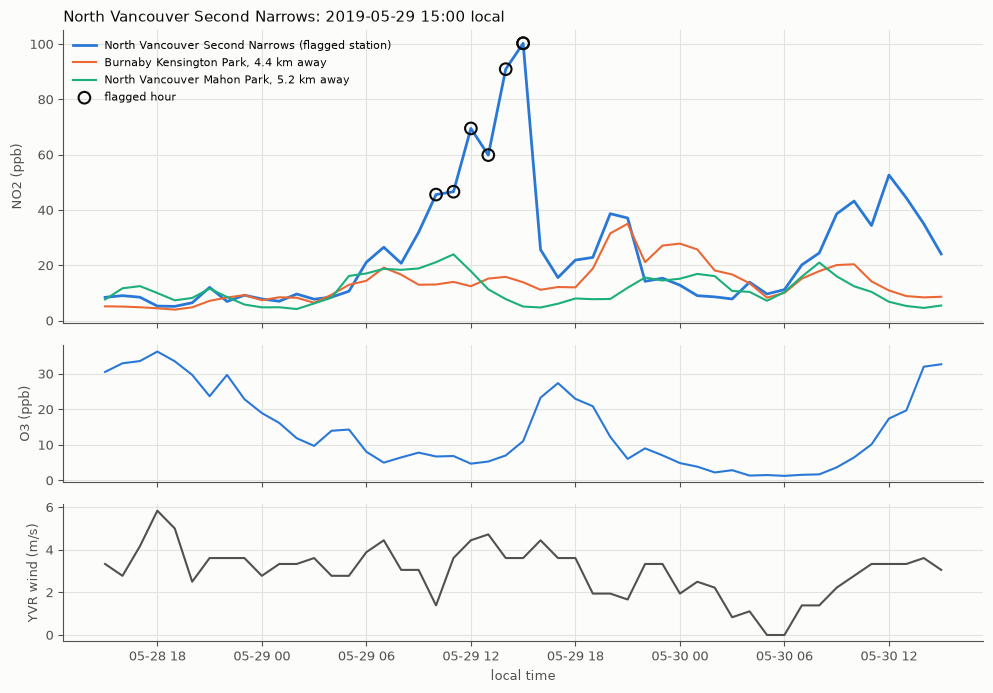

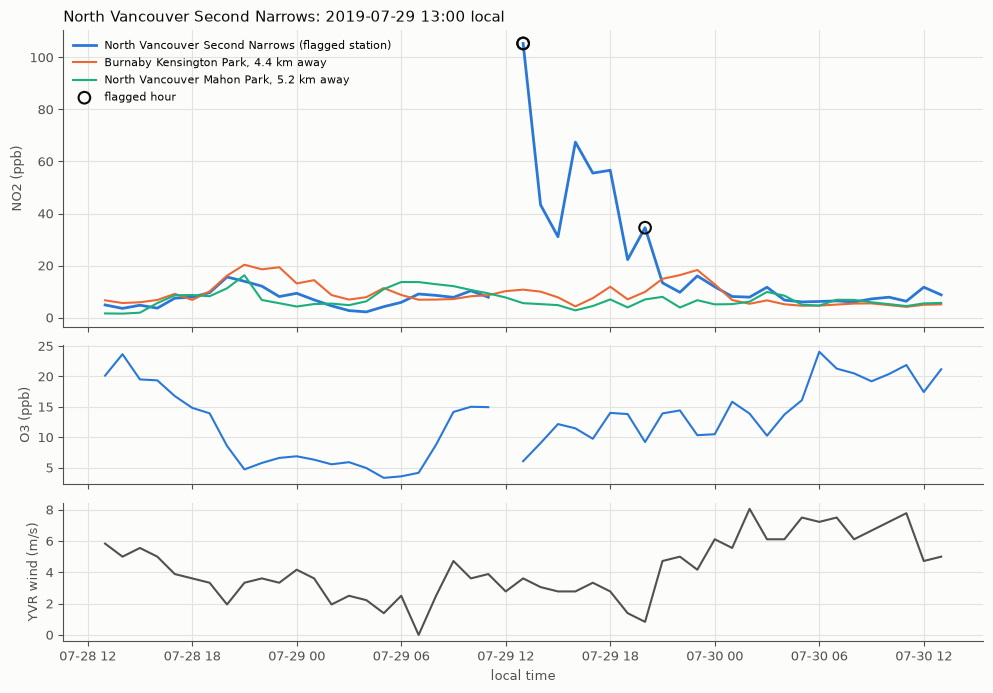

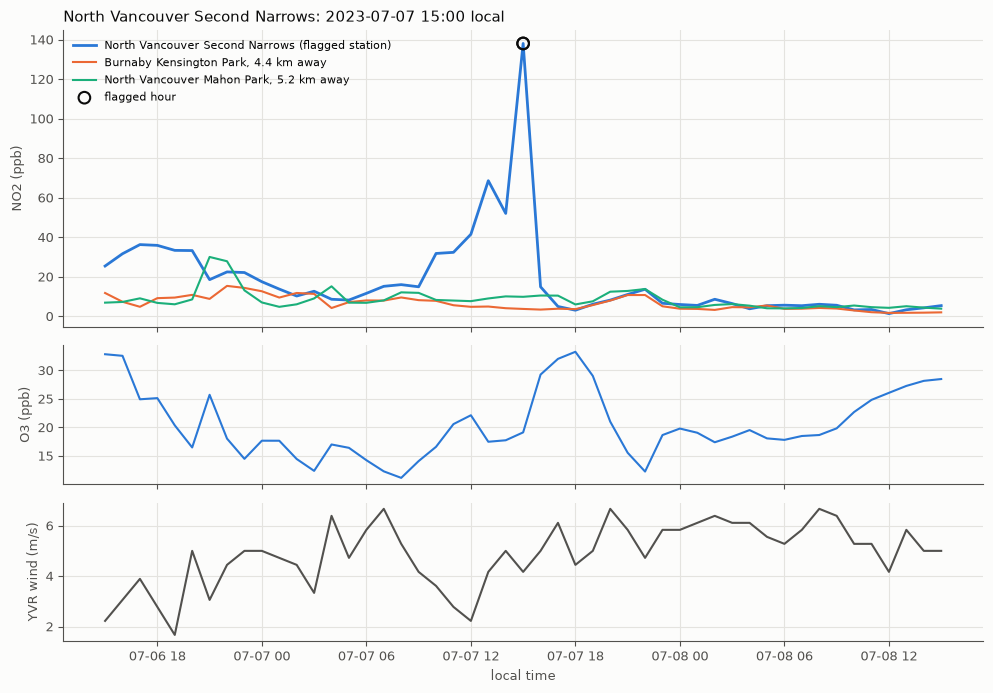

In [25]:
for row in flags[flags.check == "too_high"].itertuples():
    show_episode(row.station_id, row.start_utc, before=24, after=24)

## 15. Spikes: the 6 sharpest one-hour jumps (not the highest values)

Check: **spike**, one hour far above the hours just before and after it. A spike is measured against its own surroundings, not against a fixed level: Langdale's 22.9 ppb is an ordinary value, but the hours around it were about 3 ppb, so it is a sharp jump. Ranked by the spike score (how far the hour sits above its surroundings). ±12 hours around each.

Langdale Elementary: 22.9 ppb, score 44.0


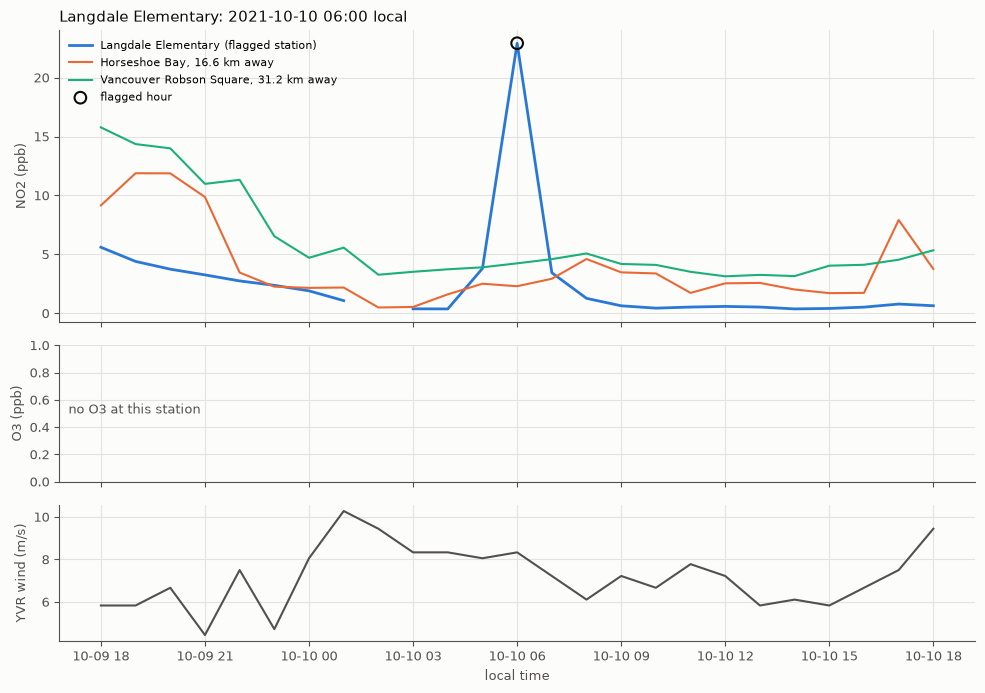

Pitt Meadows Meadowlands School: 21.0 ppb, score 39.7


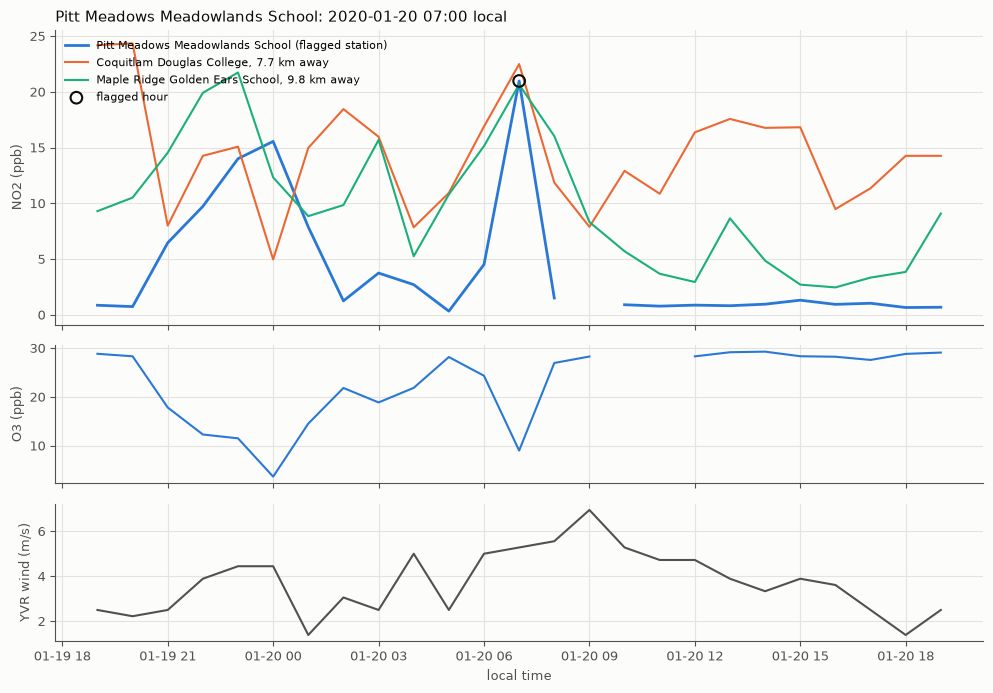

Powell River Cranberry Lake: 34.9 ppb, score 36.1


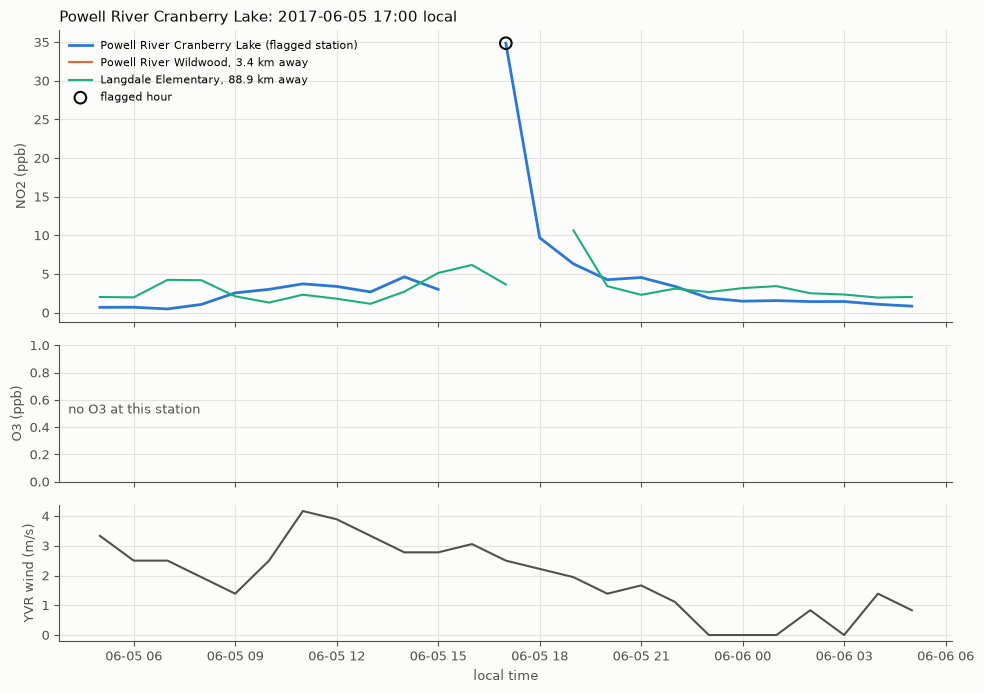

Langdale Elementary: 20.8 ppb, score 34.6


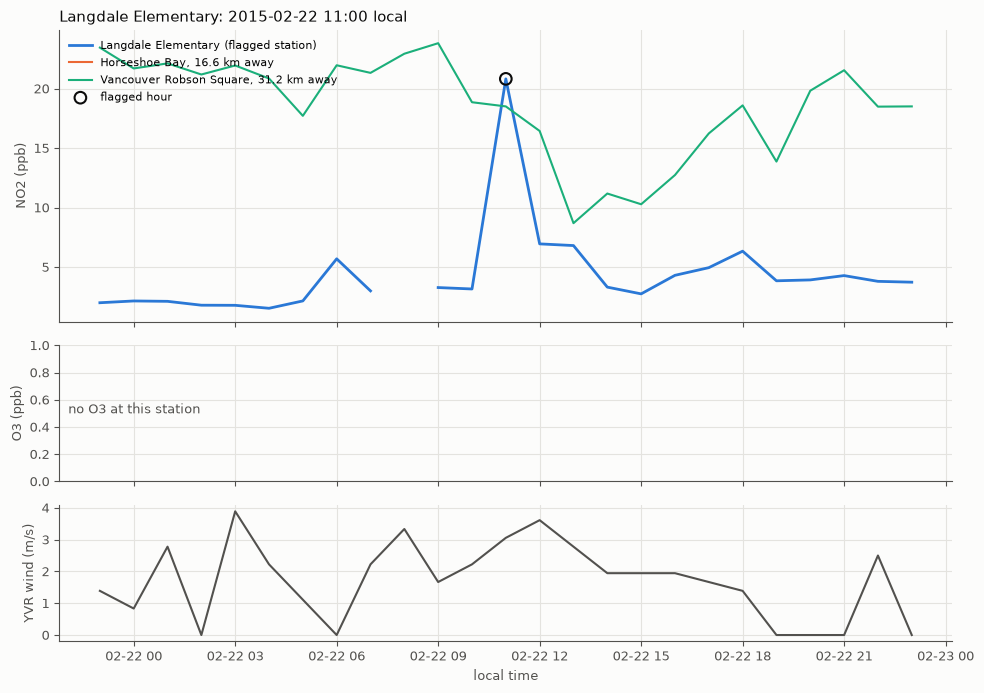

Langdale Elementary: 21.9 ppb, score 33.5


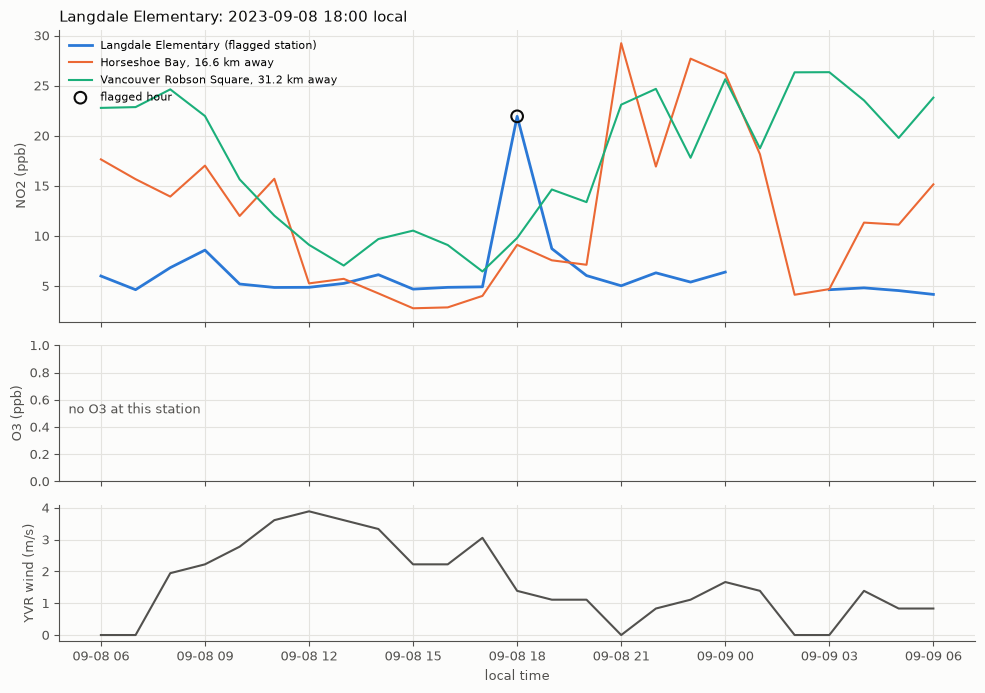

Langdale Elementary: 30.9 ppb, score 32.7


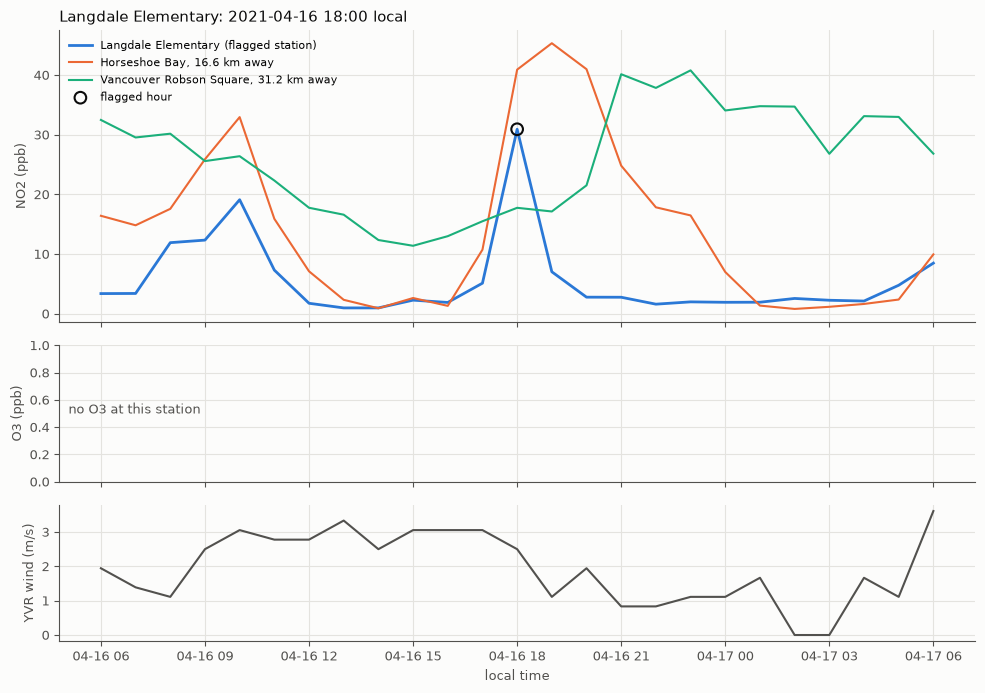

In [26]:
for row in flags[flags.check == "spike"].nlargest(6, "score").itertuples():
    print(f"{names[row.station_id]}: {row.no2_ppb:.1f} ppb, score {row.score:.1f}")
    show_episode(row.station_id, row.start_utc)

## 16. Off-neighbours: the 6 runs furthest from nearby stations

Check: **off_neighbours**, a station far from the average of its 2 nearest stations for 6 hours or more in a row. Flagged hours that follow each other at one station are grouped into runs. Shown: the 6 runs furthest from their neighbours, with ±36 hours around them.

runs: 64 | hours: 452
Agassiz Municipal Hall / Agassiz Centennial Park: 6 h from 2018-12-18 12:00 local, peak score 28.9


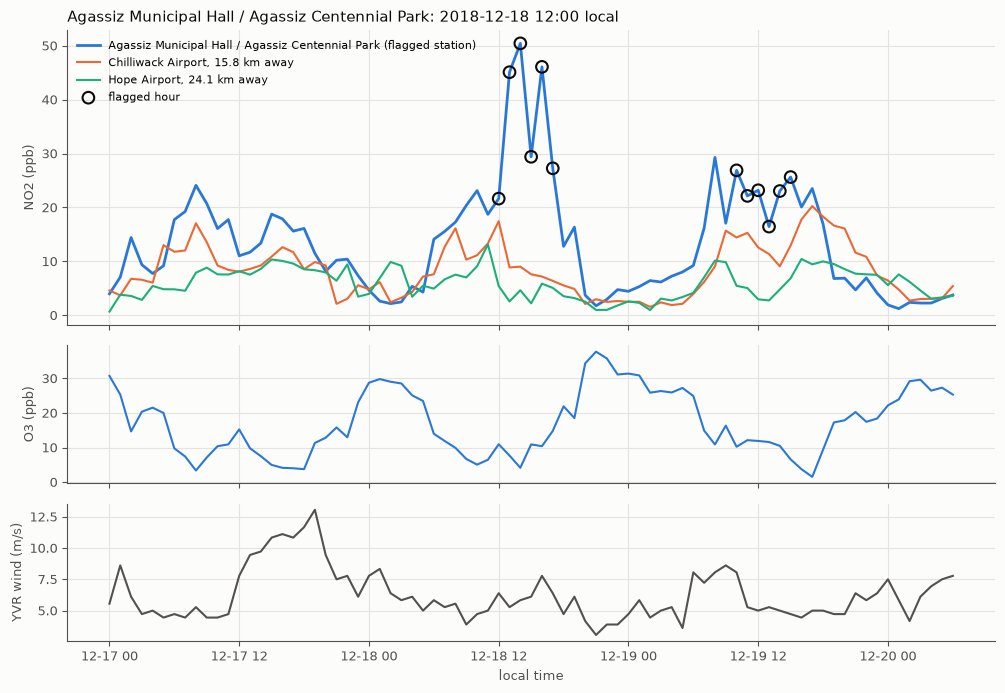

Abbotsford Central: 6 h from 2015-12-30 15:00 local, peak score 22.8


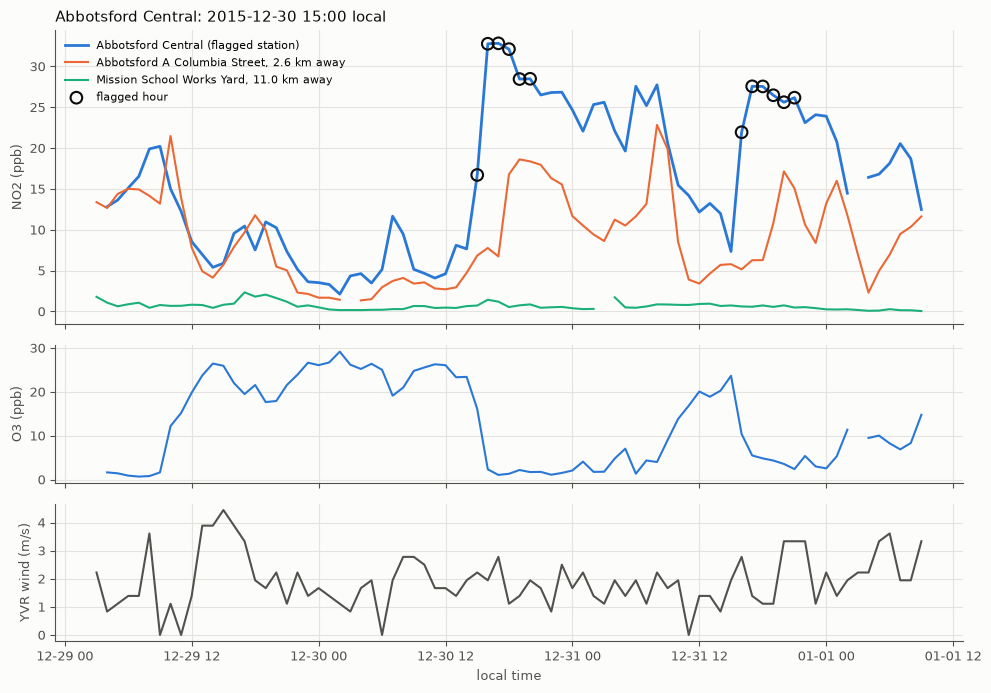

North Vancouver Second Narrows: 7 h from 2019-05-15 09:00 local, peak score 19.5


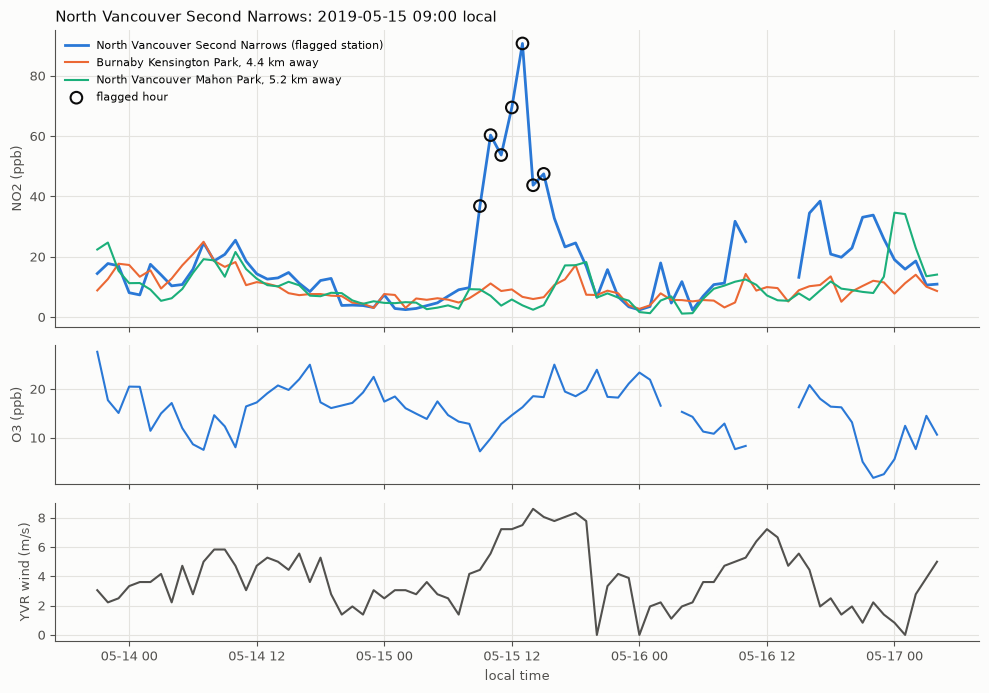

North Vancouver Second Narrows: 6 h from 2019-05-29 10:00 local, peak score 19.2


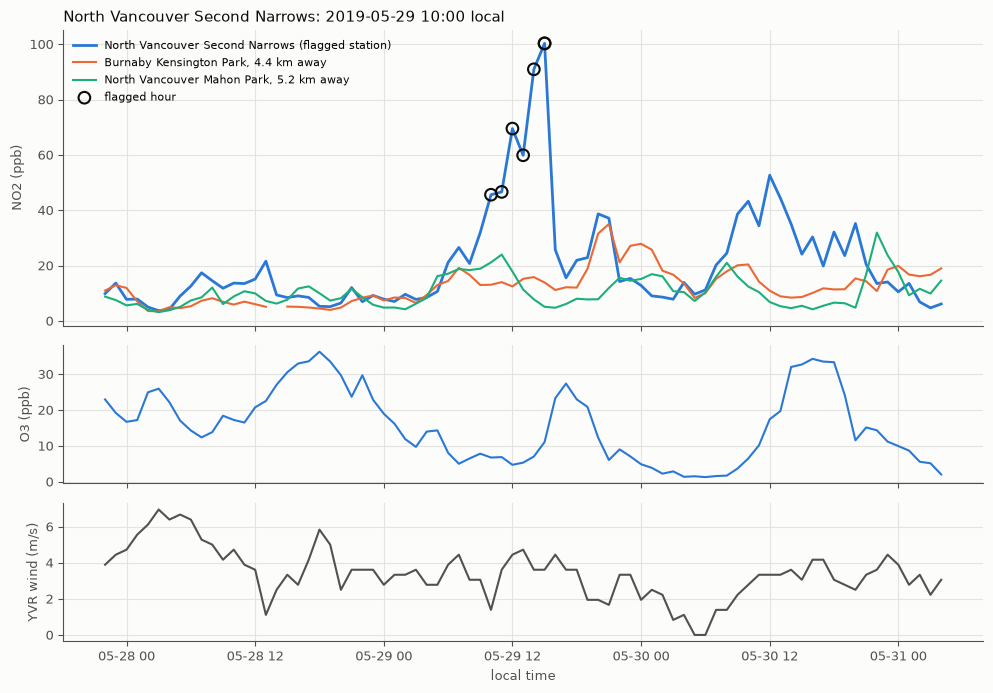

Abbotsford Central: 7 h from 2018-12-07 14:00 local, peak score 17.9


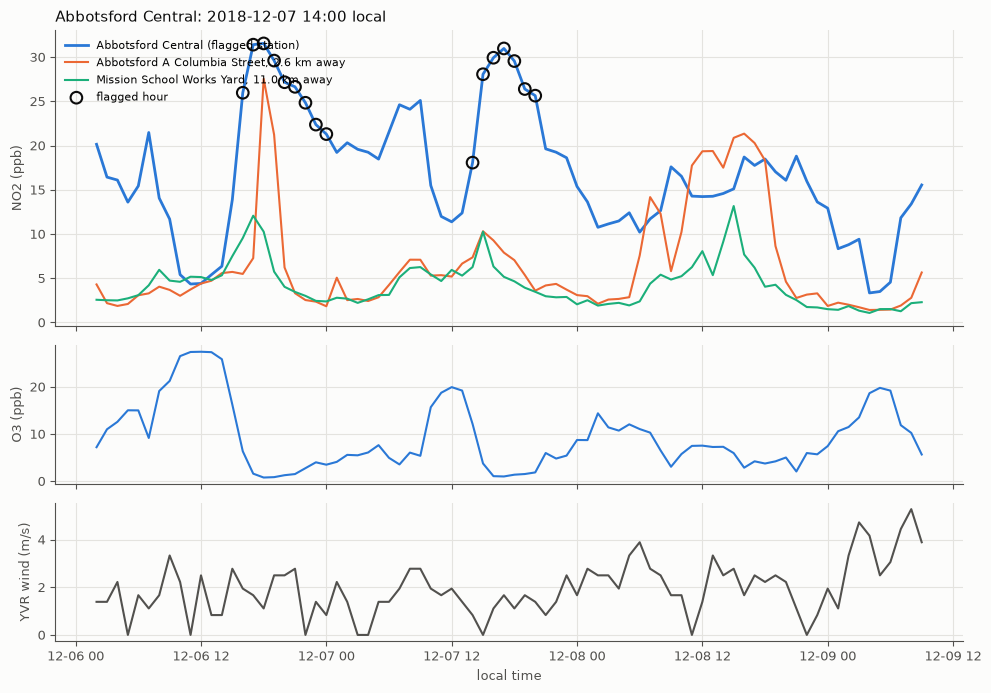

Abbotsford Central: 6 h from 2015-12-31 16:00 local, peak score 17.3


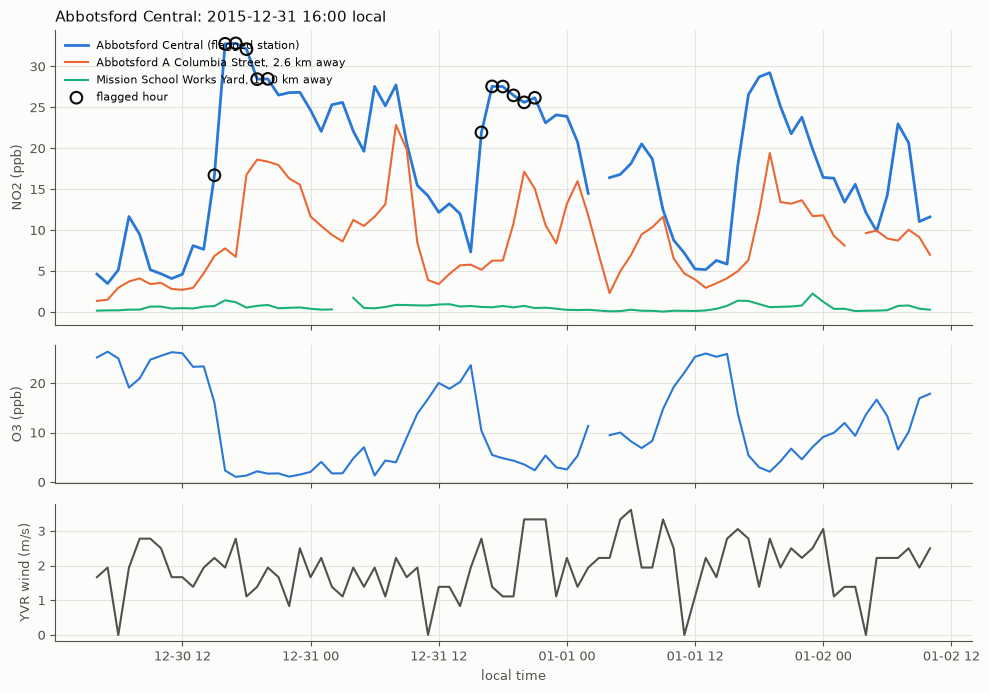

In [27]:
off = flags[flags.check == "off_neighbours"].sort_values(["station_id", "start_utc"])
new_run = (off.station_id != off.station_id.shift()) | (off.start_utc.diff() != pd.Timedelta(hours=1))
off = off.assign(run=new_run.cumsum())
runs = off.groupby("run").agg(station_id=("station_id", "first"), start=("start_utc", "first"), hours=("start_utc", "size"), peak_score=("score", "max"))
print("runs:", len(runs), "| hours:", int(runs.hours.sum()))
for row in runs.nlargest(6, "peak_score").itertuples():
    print(f"{names[row.station_id]}: {row.hours} h from {row.start.tz_convert(config.LOCAL_TZ):%Y-%m-%d %H:%M} local, peak score {row.peak_score:.1f}")
    show_episode(row.station_id, row.start, before=36, after=36 + row.hours)

## 17. Look at any flag yourself

Change `check` or `random_state` to see other cases, or call `show_episode("<station id>", "<UTC time>")` directly, e.g. `show_episode("E316370", "2023-01-10 16:00")`.

Hope Airport: 16.7 ppb at 2018-07-25 00:00 local


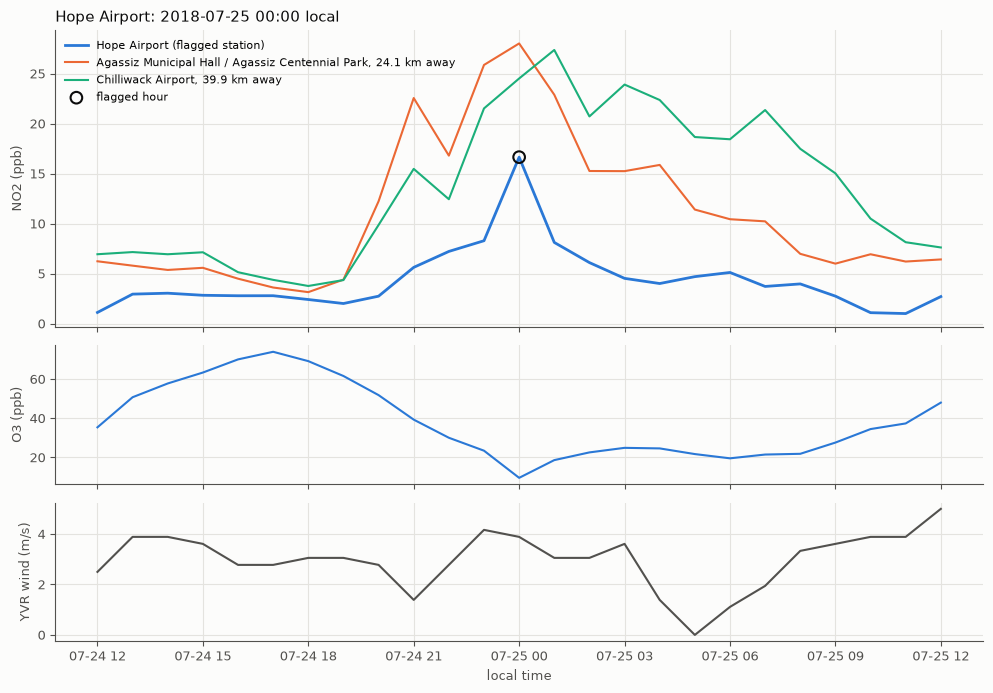

Burnaby Kensington Park: 30.1 ppb at 2015-09-13 20:00 local


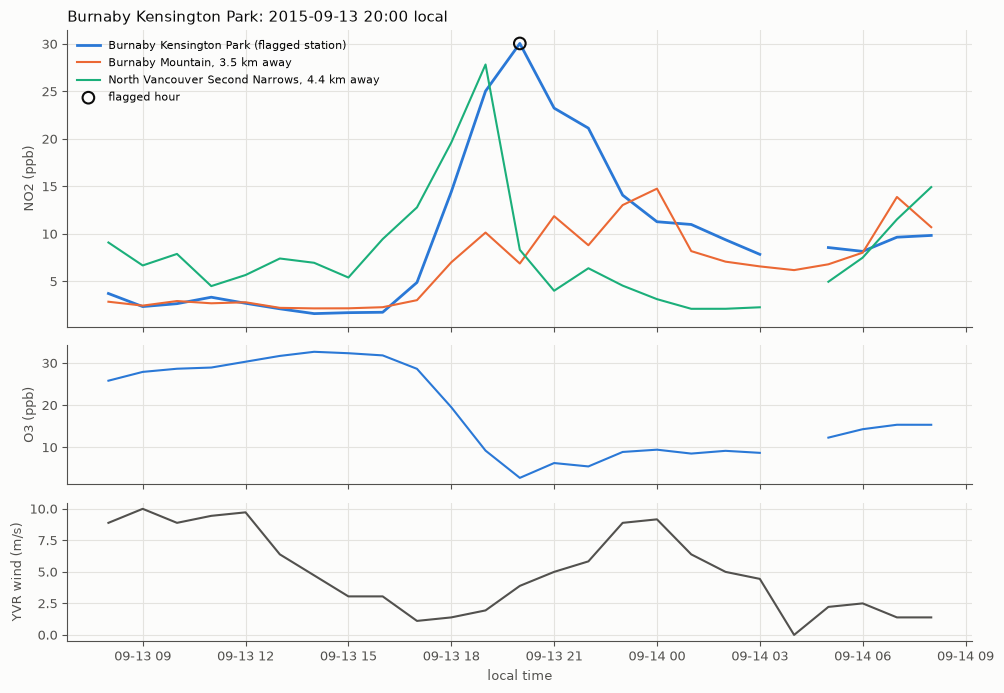

Langdale Elementary: 16.0 ppb at 2017-11-13 14:00 local


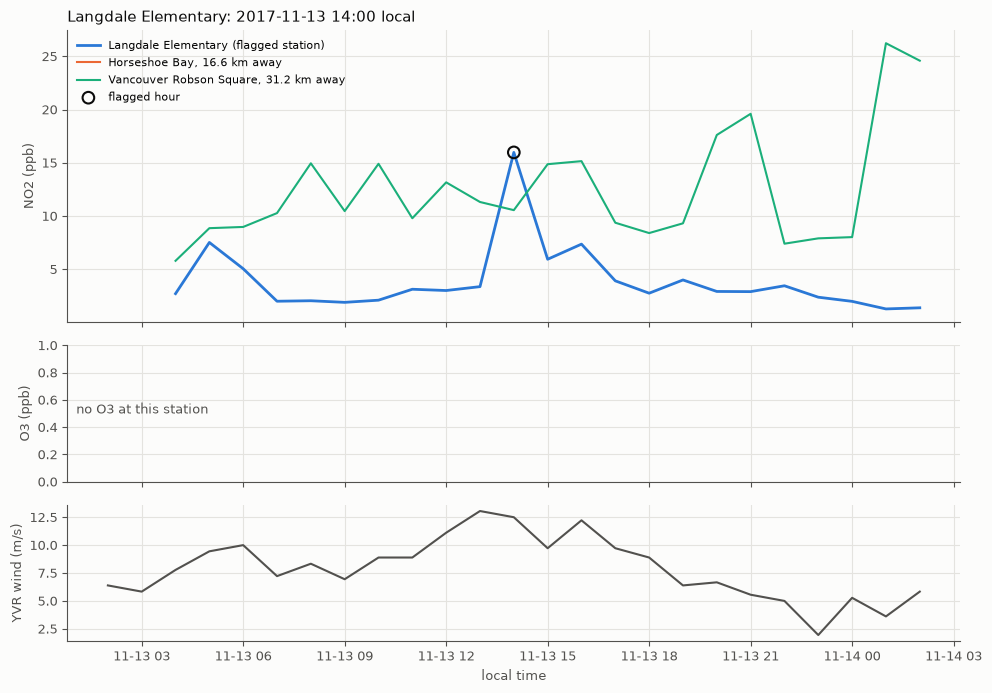

In [28]:
check = "spike" # or "off_neighbours", "too_high"
pick = flags[flags.check == check].sample(3, random_state=1)
for row in pick.itertuples():
    print(f"{names[row.station_id]}: {row.no2_ppb:.1f} ppb at {row.start_utc.tz_convert(config.LOCAL_TZ):%Y-%m-%d %H:%M} local")
    show_episode(row.station_id, row.start_utc)